# BRSET Vanilla Model Training

In [36]:
import os

os.environ["KERAS_BACKEND"] = "tensorflow"
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

import tensorflow as tf

gpus = tf.config.list_physical_devices("GPU")

for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

# Compatibility fix for kagglehub 1.0.x with kagglesdk 0.1.x.
# Must run before importing keras_cv, because keras_cv caches the kagglehub import.
import kagglesdk.kaggle_env as kaggle_env

if not hasattr(kaggle_env, "get_web_endpoint"):
    kaggle_env.get_web_endpoint = kaggle_env.get_endpoint

print("GPUs:", gpus)

GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [37]:
from pathlib import Path
import sys

ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p / "pyproject.toml").exists())
DATA_PATH = ROOT / 'data'  / 'brset' / 'processed'
ART_PATH = ROOT / 'artifacts' / 'brset'
sys.path.insert(0, str(ROOT))

In [38]:
import os
os.environ["PROTOCOL_BUFFERS_PYTHON_IMPLEMENTATION"] = "python"
os.environ["KERAS_BACKEND"] = "tensorflow" # other options: tensorflow or torch

import keras_cv
import keras
import tensorflow as tf
import cv2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("KerasCV:", keras_cv.__version__)

TensorFlow: 2.18.1
Keras: 3.14.1
KerasCV: 0.9.0


In [39]:
class CFG:
    verbose = 1  # Verbosity
    seed = 48  # Random seed
    neg_sample = 0.3 # Downsample negative class
    pos_sample = 2.13  # Upsample positive class
    preset = "efficientnetv2_b2_imagenet"  # Name of pretrained classifier
    image_size = [256, 256]  # Input image size
    epochs = 8 # Training epochs
    batch_size = 128  # Batch size
    lr_mode = "cos" # LR scheduler mode from one of "cos", "step", "exp"
    class_names = ['target']
    num_classes = 1

keras.utils.set_random_seed(CFG.seed)

# 📖 | Meta Data


In [40]:
# Train + Valid
df = pd.read_parquet(f'{DATA_PATH}/train-metadata.parquet')
display(df.head(2))

# Testing
testing_df = pd.read_parquet(f'{DATA_PATH}/test-metadata.parquet')
display(testing_df.head(2))

,image_id,patient_id,camera,comorbidities,diabetes_time_y,insuline,patient_sex,exam_eye,diabetes,nationality,...,retinal_detachment,myopic_fundus,increased_cup_disc,other,quality,age_approx,sex,illumination,anatom_site_general,target
0,img00001,1,Canon CR,diabetes1,12,yes,1,1,yes,Brazil,...,0,0,1,0,Adequate,48.0,male,1,right_eye,0
1,img00002,1,Canon CR,diabetes1,12,yes,1,2,yes,Brazil,...,0,0,1,0,Adequate,48.0,male,1,left_eye,0


,image_id,patient_id,camera,comorbidities,diabetes_time_y,insuline,patient_sex,exam_eye,diabetes,nationality,...,retinal_detachment,myopic_fundus,increased_cup_disc,other,quality,age_approx,sex,illumination,anatom_site_general,target
0,img00011,6,Canon CR,diabetes1,5,yes,1,1,yes,Brazil,...,0,0,0,0,Adequate,14.0,male,1,right_eye,0
1,img00012,6,Canon CR,diabetes1,5,yes,1,2,yes,Brazil,...,0,0,0,0,Adequate,14.0,male,1,left_eye,0


In [41]:
# Tabular feature lists + cleaning/imputation helpers
NUMERIC_FEATURES = ["age_approx", "diabetes_time_y", "exam_eye"]
CATEGORICAL_FEATURES = ["sex", "anatom_site_general", "diabetes", "insuline",
                        "nationality", "comorbidities", "camera"]

def clean_types(frame):
    frame = frame.copy()
    for c in NUMERIC_FEATURES:
        frame[c] = pd.to_numeric(frame[c], errors="coerce").astype("float32")
    for c in CATEGORICAL_FEATURES:
        frame[c] = frame[c].astype(str).replace(
            {"nan": "unknown", "None": "unknown", "": "unknown"})
    if "target" in frame:
        frame["target"] = frame["target"].astype("int32")
    return frame

def fit_imputation(frame):
    stats = {}
    for c in NUMERIC_FEATURES:
        stats[c] = float(pd.to_numeric(frame[c], errors="coerce").median())
    for c in CATEGORICAL_FEATURES:
        mode = frame[c].mode(dropna=True)
        stats[c] = mode.iloc[0] if len(mode) else "unknown"
    return stats

def apply_imputation(frame, stats):
    frame = frame.copy()
    for c in NUMERIC_FEATURES:
        frame[c] = pd.to_numeric(frame[c], errors="coerce").fillna(stats[c])
    for c in CATEGORICAL_FEATURES:
        frame[c] = frame[c].where(frame[c].notna(), stats[c]).astype(str)
    return frame

df = clean_types(df)
testing_df = clean_types(testing_df)

# ⚖️ | Handle Class Imbalance

In [42]:
print(df['target'].value_counts())

target
0    12156
1      856
Name: count, dtype: int64


# 🖼️ | Load Image Byte String


In [43]:
import h5py

training_validation_hdf5 = h5py.File(f"{DATA_PATH}/train-image.hdf5", 'r')
testing_hdf5 = h5py.File(f"{DATA_PATH}/test-image.hdf5", 'r')

Byte String: b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x01\x01\x00\x00\x01\x00\x01\x00\x00'....
Image:


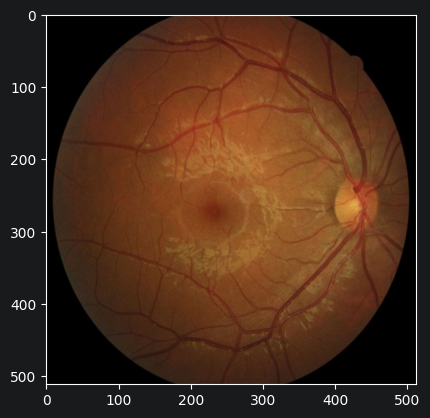

In [44]:
image_id = df.image_id.iloc[-10]

# Image as Byte String
byte_string = training_validation_hdf5[image_id][()]
print(f"Byte String: {byte_string[:20]}....")

# Convert byte string to numpy array
nparr = np.frombuffer(byte_string, np.uint8)

print("Image:")
image = cv2.imdecode(nparr, cv2.IMREAD_COLOR)[...,::-1] # reverse last axis for bgr -> rgb
plt.imshow(image);

# 🔪 | Data Split

In [45]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.utils.class_weight import compute_class_weight
import json

df = df.reset_index(drop=True)
df["fold"] = -1
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=CFG.seed)
for i, (_, validation_idx) in enumerate(sgkf.split(df, y=df.target, groups=df.patient_id)):
    df.loc[validation_idx, "fold"] = int(i)

# Split first; validation stays at natural prevalence
training_df = df.query("fold!=0").reset_index(drop=True)
validation_df = df.query("fold==0").reset_index(drop=True)
assert set(training_df.patient_id) & set(validation_df.patient_id) == set()

# Impute on training only, apply to both, persist for test
impute_stats = fit_imputation(training_df)
training_df = apply_imputation(training_df, impute_stats)
validation_df = apply_imputation(validation_df, impute_stats)
fs_dir = ART_PATH / "feature_space"
fs_dir.mkdir(parents=True, exist_ok=True)
with open(fs_dir / "impute_stats.json", "w") as f:
    json.dump(impute_stats, f)

# Resample training only
neg = training_df.query("target==0").sample(frac=CFG.neg_sample, random_state=CFG.seed)
pos = training_df.query("target==1").sample(frac=CFG.pos_sample, replace=True, random_state=CFG.seed)
training_df = pd.concat([neg, pos]).sample(frac=1.0, random_state=CFG.seed).reset_index(drop=True)

class_weights = compute_class_weight("balanced", classes=np.unique(training_df.target), y=training_df.target)
class_weights = dict(enumerate(class_weights))
print(f"# Num Train: {len(training_df)} | Num Valid: {len(validation_df)}")
print("Class Weights:", class_weights)

# Num Train: 4377 | Num Valid: 2602
Class Weights: {0: np.float64(0.75), 1: np.float64(1.5)}


In [46]:
# class distribution in training and validation
print("training:", training_df.target.value_counts(),
      "\nvalidation:", validation_df.target.value_counts(), sep='\n')

training:
target
0    2918
1    1459
Name: count, dtype: int64

validation:
target
0    2431
1     171
Name: count, dtype: int64


## 📊 | Tabular Features

In [48]:
# Categorical features to be one hot encoded
CATEGORICAL_COLUMNS = ["sex", "anatom_site_general", 'diabetes', 'quality', 'optic_disc',
                       'insuline', 'nationality', 'diabetes_time_y', 'comorbidities', 'camera' ]

# Numerical features to be normalized
NUMERIC_COLUMNS = ["age_approx", "vascular_occlusion", "other", "increased_cup_disc", 'myopic_fundus',                      'retinal_detachment',"hemorrhage", "drusens", "hypertensive_retinopathy",                                 "macular_edema", "amd", "nevus", "scar", "artifacts", "image_field", "illumination", "focus", "macula", "vessels", "exam_eye"]

# Tabular feature columns
FEAT_COLS = CATEGORICAL_COLUMNS + NUMERIC_COLUMNS

## 🍚 | DataLoader

In [49]:
# Build Training & Validation sets
from src.isic24.input_pipeline import build_dataset

print("# Training:")
training_features = dict(training_df[FEAT_COLS])
training_ids = training_df.image_id.values
training_labels = training_df.target.values
training_ds = build_dataset(training_ids, training_validation_hdf5, training_features,
                         training_labels, batch_size=CFG.batch_size,
                         shuffle=True, augment=True)

print("# Validation:")
validation_features = dict(validation_df[FEAT_COLS])
validation_ids = validation_df.image_id.values
validation_labels = validation_df.target.values
validation_ds = build_dataset(validation_ids, training_validation_hdf5, validation_features,
                         validation_labels, batch_size=CFG.batch_size,
                         shuffle=False, augment=False)


# Training:
# Validation:


In [52]:
feature_space = keras.utils.FeatureSpace(
    features={
        # Categorical features
        "sex": "string_categorical",
        "anatom_site_general": "string_categorical",
        "diabetes": "string_categorical",
        "quality": "string_categorical",
        "optic_disc": "string_categorical",
        "insuline": "string_categorical",
        "nationality": "string_categorical",
        "comorbidities": "string_categorical",
        "camera": "string_categorical",

        # Numerical features
        "age_approx": "float_normalized",
        "diabetes_time_y": "float_normalized",
        "vascular_occlusion": "float_normalized",
        "other": "float_normalized",
        "increased_cup_disc": "float_normalized",
        "myopic_fundus": "float_normalized",
        "retinal_detachment": "float_normalized",
        "hemorrhage": "float_normalized",
        "drusens": "float_normalized",
        "hypertensive_retinopathy": "float_normalized",
        "macular_edema": "float_normalized",
        "amd": "float_normalized",
        "nevus": "float_normalized",
        "scar": "float_normalized",
        "artifacts": "float_normalized",
        "image_field": "float_normalized",
        "illumination": "float_normalized",
        "focus": "float_normalized",
        "macula": "float_normalized",
        "vessels": "float_normalized",
        "exam_eye": "float_normalized",
    },
    output_mode="concat",
)

## Adapt Tabular Features

In [54]:
training_ds_with_no_labels = training_ds.map(lambda x, _: x["features"])
feature_space.adapt(training_ds_with_no_labels)

2026-06-23 20:10:56.722543: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv item cancelled. Key hash: 17480344688533492731
2026-06-23 20:10:56.722593: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv item cancelled. Key hash: 10832172683871586101
2026-06-23 20:10:56.722605: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv item cancelled. Key hash: 13501947416469195533
2026-06-23 20:10:56.722613: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv item cancelled. Key hash: 17490369203663466944
2026-06-23 20:10:56.722621: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv item cancelled. Key hash: 2097213717895541798
2026-06-23 20:10:56.722630: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv item cancelled. Key hash: 6426037971944896144
2026-06-23 20:10:56.722640: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv

In [55]:
fs_dir = ART_PATH / 'feature_space'

fs_dir.mkdir(parents=True, exist_ok=True)

feature_space.save(os.path.join(fs_dir, 'brset_feature_space.keras'))
print(f"FeatureSpace saved at: '{fs_dir}'")

FeatureSpace saved at: '/home/claudio/isic24-dum/artifacts/brset/feature_space'


In [56]:
# Apply Feature Processing
training_ds = training_ds.map(
    lambda x, y: ({"images": x["images"],
                   "features": feature_space(x["features"])}, y), num_parallel_calls=tf.data.AUTOTUNE)

validation_ds = validation_ds.map(
    lambda x, y: ({"images": x["images"],
                   "features": feature_space(x["features"])}, y), num_parallel_calls=tf.data.AUTOTUNE)

In [57]:
# loss & metric
auc = keras.metrics.AUC(name='auc')
loss = keras.losses.BinaryCrossentropy(label_smoothing=0.02)

# 🤖 | Modeling

In [58]:
# Define input layers
image_input = keras.Input(shape=(*CFG.image_size, 3), name="images")
feat_input = keras.Input(shape=(feature_space.get_encoded_features().shape[1],), name="features")
inp = {"images":image_input, "features":feat_input}

# Branch for image input
backbone = keras_cv.models.EfficientNetV2Backbone.from_preset(CFG.preset)
x1 = backbone(image_input)
x1 = keras.layers.GlobalAveragePooling2D()(x1)
x1 = keras.layers.Dropout(0.2)(x1)

# Branch for tabular/feature input
x2 = keras.layers.Dense(96, activation="selu")(feat_input)
x2 = keras.layers.Dense(128, activation="selu")(x2)
x2 = keras.layers.Dropout(0.1)(x2)

# Concatenate both branches
concat = keras.layers.Concatenate()([x1, x2])

# Output layer
out = keras.layers.Dense(1, activation="sigmoid", dtype="float32")(concat)

# Build model
model = keras.models.Model(inp, out)

# Compile the model
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss=loss,
    metrics=[auc],
)

# Model Summary
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ images (InputLayer) │ (None, 256, 256,  │          0 │ -                 │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ features            │ (None, 156)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficient_net_v2b2… │ (None, 8, 8,      │  8,769,374 │ images[0][0]      │
│ (EfficientNetV2Bac… │ 1408)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 96)        │     15,072 │ features[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1408)      │          0 │ efficient_net_v2… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 128)       │     12,416 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 1408)      │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 128)       │          0 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 1536)      │          0 │ dropout_2[0][0],  │
│ (Concatenate)       │                   │            │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 1)         │      1,537 │ concatenate_1[0]… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 8,798,399 (33.56 MB)

 Trainable params: 8,716,111 (33.25 MB)

 Non-trainable params: 82,288 (321.44 KB)

In [22]:
# keras.utils.plot_model(model, show_shapes=True, show_layer_names=True, dpi=60)

# ⚓ | LR Schedule

## Sanity Checks

2026-06-23 20:12:34.066500: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv item cancelled. Key hash: 9398631491088232735
2026-06-23 20:12:34.066603: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv item cancelled. Key hash: 13787248871582413035
2026-06-23 20:12:34.066616: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv item cancelled. Key hash: 9736640079327983745
2026-06-23 20:12:34.066627: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv item cancelled. Key hash: 8585083404381945587
2026-06-23 20:12:34.066636: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv item cancelled. Key hash: 10217607497219895656
2026-06-23 20:12:34.066644: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv item cancelled. Key hash: 13461889435600941954
2026-06-23 20:12:34.066656: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv 

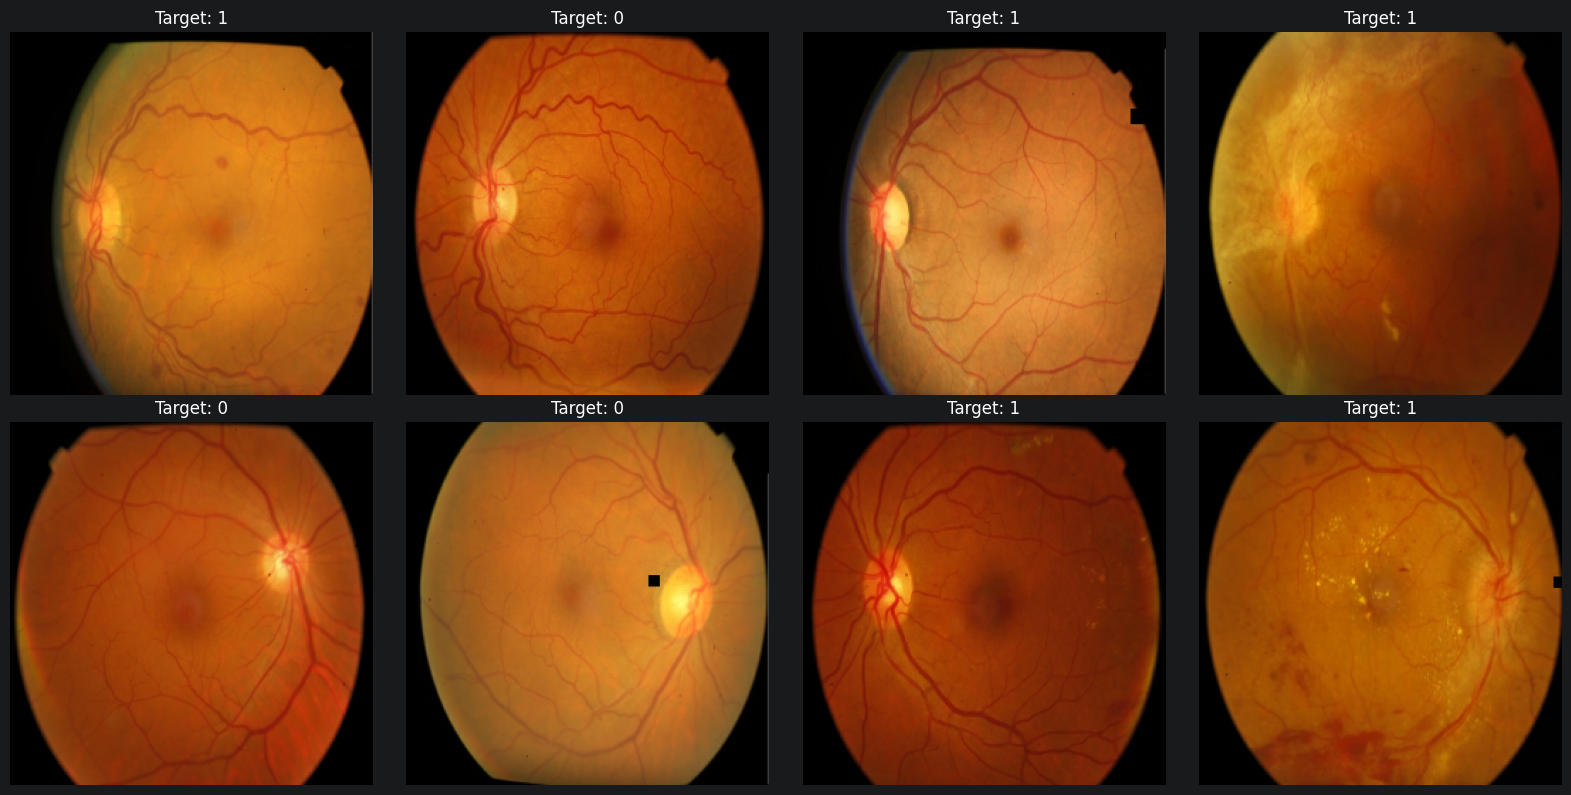

In [59]:
inputs, targets = next(iter(training_ds))
images = inputs["images"]
num_images, NUMERIC_COLUMNS = 8, 4

plt.figure(figsize=(4 * NUMERIC_COLUMNS, num_images // NUMERIC_COLUMNS * 4))
for i, (image, target) in enumerate(zip(images[:num_images], targets[:num_images])):
    plt.subplot(num_images // NUMERIC_COLUMNS, NUMERIC_COLUMNS, i + 1)
    image = image.numpy().astype("float32")
    target= target.numpy().astype("int32")[0]

    image = (image - image.min()) / (image.max() + 1e-4)

    plt.imshow(image)
    plt.title(f"Target: {target}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [60]:
import math
import matplotlib.pyplot as plt

def get_lr_callback(batch_size=8, mode='cos', epochs=20, plot=False):
    lr_start, lr_max, lr_min = 2.5e-5, 5e-6 * batch_size, 0.8e-5
    lr_ramp_ep, lr_sus_ep, lr_decay = 3, 0, 0.75

    def lrfn(epoch):  # Learning rate update function
        if epoch < lr_ramp_ep: lr = (lr_max - lr_start) / lr_ramp_ep * epoch + lr_start
        elif epoch < lr_ramp_ep + lr_sus_ep: lr = lr_max
        elif mode == 'exp': lr = (lr_max - lr_min) * lr_decay**(epoch - lr_ramp_ep - lr_sus_ep) + lr_min
        elif mode == 'step': lr = lr_max * lr_decay**((epoch - lr_ramp_ep - lr_sus_ep) // 2)
        elif mode == 'cos':
            decay_total_epochs, decay_epoch_index = epochs - lr_ramp_ep - lr_sus_ep + 3, epoch - lr_ramp_ep - lr_sus_ep
            phase = math.pi * decay_epoch_index / decay_total_epochs
            lr = (lr_max - lr_min) * 0.5 * (1 + math.cos(phase)) + lr_min
        return lr

    if plot:  # Plot lr curve if plot is True
        plt.figure(figsize=(10, 5))
        plt.plot(np.arange(epochs), [lrfn(epoch) for epoch in np.arange(epochs)], marker='o')
        plt.xlabel('epoch'); plt.ylabel('lr')
        plt.title('LR Scheduler')
        plt.show()

    return keras.callbacks.LearningRateScheduler(lrfn, verbose=False)  # Create lr callback

lr_cb = get_lr_callback(CFG.batch_size, mode=CFG.lr_mode, plot=False)

In [61]:
model_name = "brset_best_vanilla_model.keras"
MODEL_PATH = ART_PATH / 'vanilla'
model_filepath = os.path.join(MODEL_PATH, model_name)

ckpt_cb = keras.callbacks.ModelCheckpoint(
    model_filepath,   # Filepath where the model will be saved.
    monitor="val_auc",    # Metric to monitor (validation AUC in this case).
    save_best_only=True,  # Save only the model with the best performance.
    save_weights_only=False,  # Save the entire model (not just the weights).
    mode="max",           # The model with the maximum 'val_auc' will be saved.
)

# 🚂 | Training

In [62]:
history = model.fit(
    training_ds,
    epochs=CFG.epochs,
    callbacks=[lr_cb, ckpt_cb],
    validation_data=validation_ds,
    verbose=CFG.verbose,
    class_weight=class_weights,
)

Epoch 1/8
15/35 ━━━━━━━━━━━━━━━━━━━━ 5s 289ms/step - auc: 0.3666 - loss: 0.7273 

E0000 00:00:1782238448.312864 2840238 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1782238448.512540 2840238 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1782238448.937376 2840238 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1782238449.138824 2840238 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1782238449.335980 2840238 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:0

35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - auc: 0.4149 - loss: 0.7195   

E0000 00:00:1782238492.352161 2840247 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1782238492.589085 2840247 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1782238492.792749 2840247 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1782238493.214702 2840247 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1782238493.413110 2840247 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:0

35/35 ━━━━━━━━━━━━━━━━━━━━ 135s 2s/step - auc: 0.4975 - loss: 0.7023 - val_auc: 0.4013 - val_loss: 19.4610 - learning_rate: 2.5000e-05
Epoch 2/8
35/35 ━━━━━━━━━━━━━━━━━━━━ 15s 399ms/step - auc: 0.9016 - loss: 0.4427 - val_auc: 0.8966 - val_loss: 0.2584 - learning_rate: 2.3000e-04
Epoch 3/8
35/35 ━━━━━━━━━━━━━━━━━━━━ 15s 404ms/step - auc: 0.9752 - loss: 0.2468 - val_auc: 0.9631 - val_loss: 0.6439 - learning_rate: 4.3500e-04
Epoch 4/8
35/35 ━━━━━━━━━━━━━━━━━━━━ 14s 367ms/step - auc: 0.9929 - loss: 0.1575 - val_auc: 0.9606 - val_loss: 0.9008 - learning_rate: 6.4000e-04
Epoch 5/8
35/35 ━━━━━━━━━━━━━━━━━━━━ 15s 403ms/step - auc: 0.9985 - loss: 0.1075 - val_auc: 0.9772 - val_loss: 1.1162 - learning_rate: 6.3611e-04
Epoch 6/8
35/35 ━━━━━━━━━━━━━━━━━━━━ 14s 369ms/step - auc: 0.9996 - loss: 0.0873 - val_auc: 0.9606 - val_loss: 1.2418 - learning_rate: 6.2453e-04
Epoch 7/8
35/35 ━━━━━━━━━━━━━━━━━━━━ 14s 368ms/step - auc: 0.9998 - loss: 0.0800 - val_auc: 0.9728 - val_loss: 1.3413 - learning_rate: 

In [63]:
# save model
model.save(model_filepath, include_optimizer=True)
print(f"model saved at: {model_filepath}")

model saved at: /home/claudio/isic24-dum/artifacts/brset/vanilla/brset_best_vanilla_model.keras


## Visualize AUC with Epochs

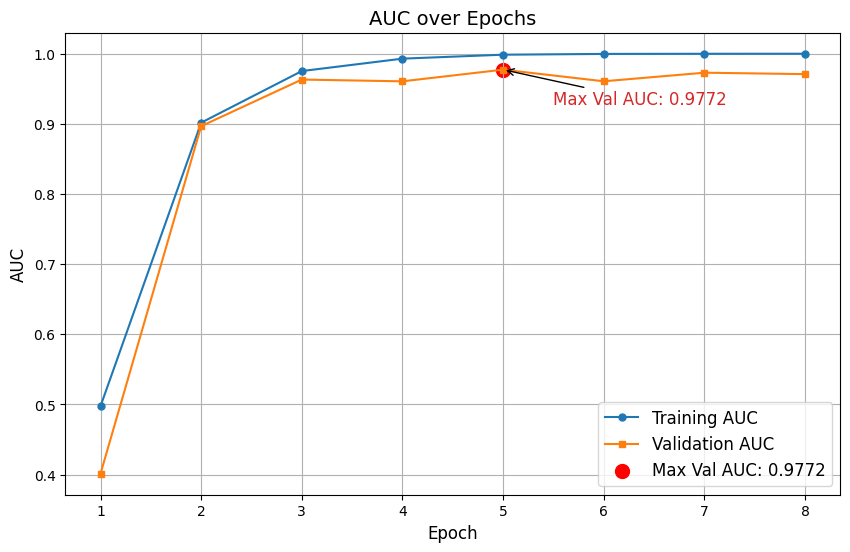

In [64]:
# Extract AUC and validation AUC from history
auc = history.history['auc']
val_auc = history.history['val_auc']
epochs = range(1, len(auc) + 1)

# Find the epoch with the maximum val_auc
max_val_auc_epoch = np.argmax(val_auc)
max_val_auc = val_auc[max_val_auc_epoch]

# Plotting
plt.figure(figsize=(10, 6))
plt.plot(epochs, auc, 'o-', label='Training AUC', markersize=5, color='tab:blue')
plt.plot(epochs, val_auc, 's-', label='Validation AUC', markersize=5, color='tab:orange')

# Highlight the max val_auc
plt.scatter(max_val_auc_epoch + 1, max_val_auc, color='red', s=100, label=f'Max Val AUC: {max_val_auc:.4f}')
plt.annotate(f'Max Val AUC: {max_val_auc:.4f}',
             xy=(max_val_auc_epoch + 1, max_val_auc),
             xytext=(max_val_auc_epoch + 1 + 0.5, max_val_auc - 0.05),
             arrowprops=dict(facecolor='black', arrowstyle="->"),
             fontsize=12,
             color='tab:red')

# Enhancing the plot
plt.title('AUC over Epochs', fontsize=14)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('AUC', fontsize=12)
plt.legend(loc='lower right', fontsize=12)
plt.grid(True)
plt.xticks(epochs)

# Show the plot
plt.show()

# 📋 | Result

In [65]:
# Best Result
best_score = max(history.history['val_auc'])
best_epoch = np.argmax(history.history['val_auc']) + 1
print("#" * 10 + " Result " + "#" * 10)
print(f"Best AUC: {best_score:.5f}")
print(f"Best Epoch: {best_epoch}")
print("#" * 28)

########## Result ##########
Best AUC: 0.97717
Best Epoch: 5
############################


# 🧪 | Prediction

In [66]:
model.load_weights(model_filepath)

In [67]:
# Build Testing Dataset
print("# Testing:")
import json
with open(ART_PATH / "feature_space" / "impute_stats.json") as f:
    impute_stats = json.load(f)
testing_df = apply_imputation(testing_df, impute_stats)

testing_features = dict(testing_df[FEAT_COLS])
testing_ids = testing_df.image_id.values
testing_ds = build_dataset(testing_ids, testing_hdf5,
                        testing_features, batch_size=CFG.batch_size,
                         shuffle=False, augment=False, cache=False)

# Apply feature space processing
testing_ds = testing_ds.map(
    lambda x: {"images": x["images"],
               "features": feature_space(x["features"])}, num_parallel_calls=tf.data.AUTOTUNE)

# Testing:


In [69]:
preds = model.predict(testing_ds).squeeze()

# set threshold
threshold = 0.5

# count positives
n_pos = np.sum(preds >= threshold)

print(f"Positive predictions: {n_pos}/{len(preds)}")
print(f"{100 * n_pos / len(preds):.2f}% positive predictions")


26/26 ━━━━━━━━━━━━━━━━━━━━ 12s 272ms/step
Positive predictions: 253/3254
7.78% positive predictions


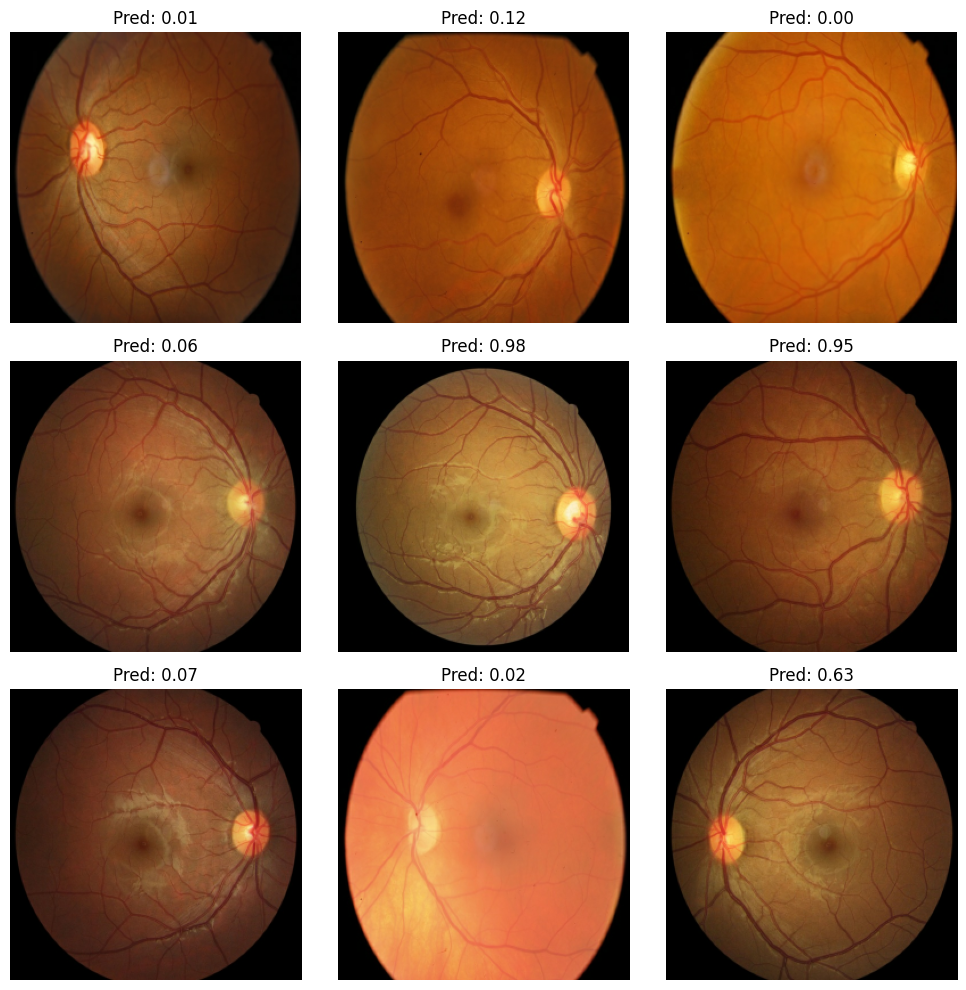

In [70]:
inputs = next(iter(testing_ds))
images = inputs["images"]

idxs = np.random.choice(len(images), size=9, replace=False)

plt.figure(figsize=(10, 10))
for j, i in enumerate(idxs):
    plt.subplot(3, 3, j + 1)
    plt.imshow(images[i])
    plt.title(f'Pred: {preds[i]:.2f}')
    plt.axis('off')
plt.tight_layout(); plt.show()

4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step


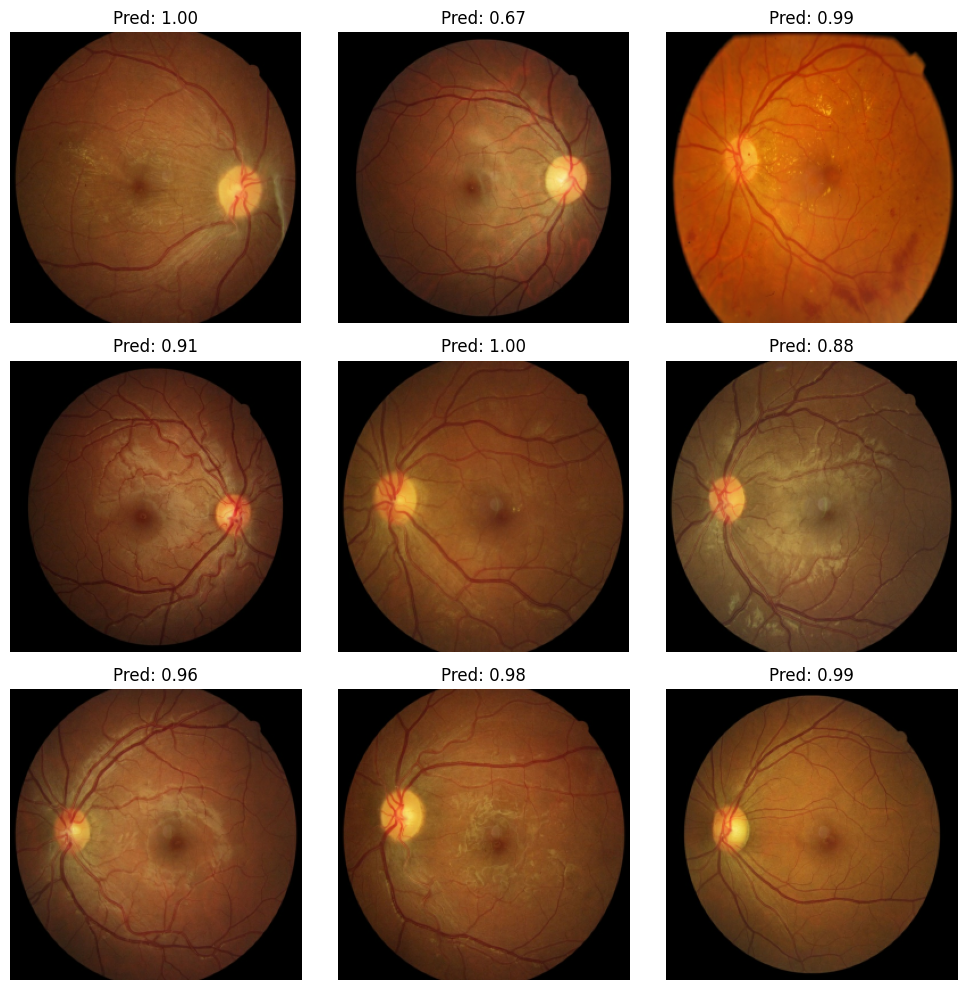

In [71]:
inputs = next(iter(testing_ds))
preds_batch = model.predict(inputs).squeeze()

images = inputs["images"]

pos_idxs = np.where(preds_batch >= 0.5)[0]

if len(pos_idxs) > 9:
    idxs = np.random.choice(pos_idxs, 9, replace=False)
else:
    idxs = pos_idxs

plt.figure(figsize=(10, 10))
for j, i in enumerate(idxs):
    plt.subplot(3, 3, j + 1)
    plt.imshow(images[i])
    plt.title(f'Pred: {preds_batch[i]:.2f}')
    plt.axis('off')

plt.tight_layout()
plt.show()

In [72]:
# create a only positives predictions dataset
all_inputs = list(testing_ds.unbatch().as_numpy_iterator())
images = np.stack([x["images"] for x in all_inputs])
metadata = np.stack([x["metadata"] for x in all_inputs])

# predict
preds = model.predict({"images": images, "metadata": metadata}).squeeze()

# filter positives
pos_mask = preds >= 0.5
images_pos = images[pos_mask]
metadata_pos = metadata[pos_mask]

# rebuild dataset
positives_ds = tf.data.Dataset.from_tensor_slices({
    "images": images_pos,
    "metadata": metadata_pos
})

KeyError: 'metadata'